# Proyek Spektroskopi Raman: Simulasi Fisika Molekular
## Pemodelan Spektrum Raman Maju (Forward Modeling) dari Prinsip Pertama

**Kelompok:**
- Pradithya Putra Galang Islami (NIM: 182241014)
- Naufal Lutfian Hakim (NIM: 182241015)
- Hendra Maulana (NIM: 182241043)

**Dosen Pembimbing:** Drs. Adri Supardi, M.S.  
**Afiliasi:** Departemen Fisika, Fakultas Sains dan Teknologi, Universitas Airlangga

---
### 1. Landasan Fisika Pemodelan
Spektroskopi Raman dimodelkan melalui ekspansi polarizabilitas terhadap koordinat normal vibrasi $Q_k$:
$$\alpha(Q) = \alpha_0 + \sum_k \left(\frac{\partial \alpha}{\partial Q_k}\right)_0 Q_k + \dots$$
Aktivitas Raman sebanding dengan kuadrat turunan polarizabilitas $R_k = |(\partial\alpha/\partial Q_k)_0|^2$.
Frekuensi vibrasi harmonik diturunkan dari konstanta pegas ikatan $k$ dan massa tereduksi $\mu$:
$$\tilde{\nu}_v = \frac{1}{2\pi c}\sqrt{\frac{k}{\mu}}$$
Rasio intensitas garis anti-Stokes terhadap Stokes mengikuti distribusi Boltzmann dan faktor frekuensi kuartik:
$$\frac{I_{AS}}{I_S} = \left(\frac{\tilde{\nu}_0 + \tilde{\nu}_v}{\tilde{\nu}_0 - \tilde{\nu}_v}\right)^4 \exp\left(-\frac{h c \tilde{\nu}_v}{k_B T}\right)$$

In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd()))
from src.raman_physics import (
    reduced_mass_diatomic, harmonic_wavenumber, force_constant_from_wavenumber,
    laser_wavelength_to_wavenumber, stokes_anti_stokes_ratio,
    swcnt_diameter_from_chiral, swcnt_is_metallic, swcnt_rbm_wavenumber,
    graphene_2d_dispersion, laser_wavelength_to_energy_ev
)
from src.molecular_simulation import MolecularRamanSimulator
from src.plotting import apply_axes_style, save_publication_figure, COLORS

OUTPUT_SIM_DIR = Path("outputs/simulation")
OUTPUT_TABLES_DIR = Path("outputs/tables")
OUTPUT_FIGURES_DIR = Path("outputs/figures")
for d in [OUTPUT_SIM_DIR, OUTPUT_TABLES_DIR, OUTPUT_FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Inisialisasi modul simulasi molekular selesai.")

Inisialisasi modul simulasi molekular selesai.


### 2. Penurunan Numerik Konstanta Pegas dan Bilangan Gelombang Harmonik
Menghitung massa tereduksi $\mu$ dan konstanta pegas $k$ untuk ikatan C-C (Grafena/CNT) dan B-N (h-BN).

In [2]:
# C-C in Graphene / CNT
m_C = 12.011
mu_cc = reduced_mass_diatomic(m_C, m_C)
nu_g_target = 1582.4
k_cc = force_constant_from_wavenumber(nu_g_target, mu_cc)

# B-N in h-BN
m_B, m_N = 10.811, 14.007
mu_bn = reduced_mass_diatomic(m_B, m_N)
nu_hbn_target = 1366.8
k_bn = force_constant_from_wavenumber(nu_hbn_target, mu_bn)

print(f"Ikatan C-C (Grafena G-mode): mu = {mu_cc:.4e} kg, k = {k_cc:.2f} N/m, nu = {nu_g_target:.1f} cm^-1")
print(f"Ikatan B-N (h-BN E2g-mode): mu = {mu_bn:.4e} kg, k = {k_bn:.2f} N/m, nu = {nu_hbn_target:.1f} cm^-1")

Ikatan C-C (Grafena G-mode): mu = 9.9724e-27 kg, k = 886.00 N/m, nu = 1582.4 cm^-1
Ikatan B-N (h-BN E2g-mode): mu = 1.0132e-26 kg, k = 671.59 N/m, nu = 1366.8 cm^-1


### 3. Simulasi Ketergantungan Temperatur (Rasio Stokes dan Anti-Stokes)
Mensimulasikan evolusi spektrum Raman pada rentang temperatur $T = 100\text{ K}, 300\text{ K}, 500\text{ K}, 800\text{ K}$ untuk mode $G$ grafena.

Saved figure: simulation_temperature_series.pdf & simulation_temperature_series.png


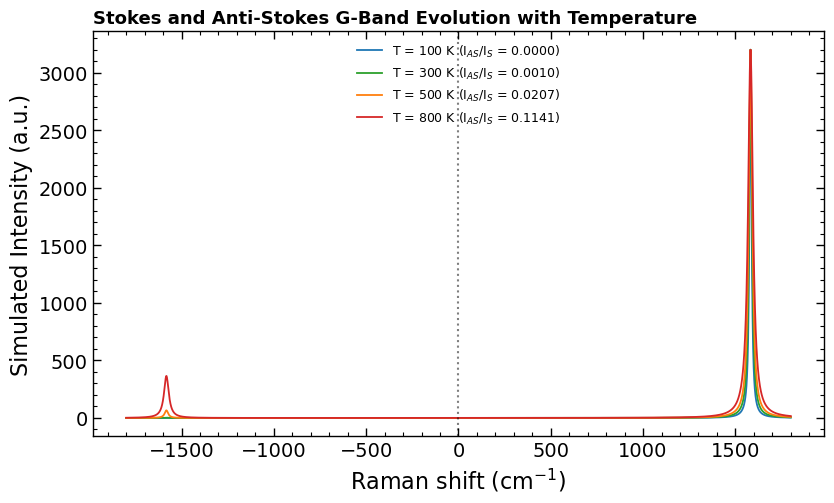

In [3]:
simulator = MolecularRamanSimulator(laser_wavelength_nm=532.0, temperature_k=300.0)
wn_full = np.linspace(-1800.0, 1800.0, 3601)

temperatures = [100.0, 300.0, 500.0, 800.0]
temp_results = simulator.simulate_temperature_series(wn_full, temperatures=temperatures)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
colors_t = {100.0: "#1f77b4", 300.0: "#2ca02c", 500.0: "#ff7f0e", 800.0: "#d62728"}

for T in temperatures:
    r = temp_results[T]["ratio_anti_to_stokes"]
    tot_spec = temp_results[T]["stokes_curve"] + temp_results[T]["anti_stokes_curve"]
    ax.plot(wn_full, tot_spec, color=colors_t[T], lw=1.3, label=f"T = {T:.0f} K (I$_{{AS}}$/I$_S$ = {r:.4f})")

apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Simulated Intensity (a.u.)")
ax.set_title("Stokes and Anti-Stokes G-Band Evolution with Temperature", loc="left", fontsize=13, fontweight="bold")
ax.legend(frameon=False, fontsize=9, loc="upper center")
ax.axvline(0, color="k", ls=":", alpha=0.5, label="Rayleigh line (0 cm$^{-1}$)")

save_publication_figure(fig, "simulation_temperature_series")
plt.show()

### 4. Simulasi Dispersi Resonansi Ganda Pita 2D Grafena
Pita 2D grafena berasal dari proses resonansi ganda orde kedua inter-valley dua fonon iTO. Posisinya bergeser secara linear terhadap energi foton laser datang dengan dispersi $\partial\omega_{2D}/\partial E_L \approx 100\text{ cm}^{-1}/\text{eV}$.

Saved figure: simulation_laser_dispersion.pdf & simulation_laser_dispersion.png


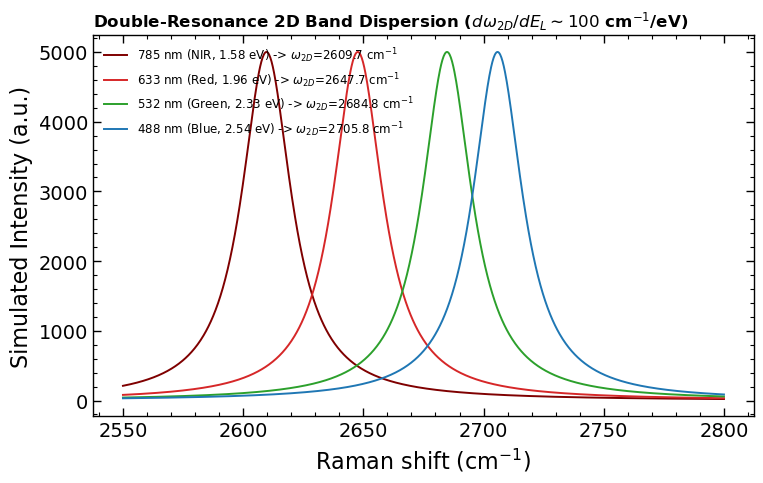

In [4]:
lasers = [
    (785.0, 1.5794, "#7f0000", "785 nm (NIR, 1.58 eV)"),
    (632.8, 1.9593, "#d62728", "633 nm (Red, 1.96 eV)"),
    (532.0, 2.3305, "#2ca02c", "532 nm (Green, 2.33 eV)"),
    (488.0, 2.5407, "#1f77b4", "488 nm (Blue, 2.54 eV)")
]

fig, ax = plt.subplots(figsize=(7.8, 5.0))
wn_2d_window = np.linspace(2550.0, 2800.0, 1000)

for lam, el, c, lbl in lasers:
    w_disp = graphene_2d_dispersion(el, base_2d_cm1=2684.8)
    sim_2d = simulator.build_spectrum_from_modes(wn_2d_window, [
        {"center": w_disp, "fwhm": 25.0, "activity": 5000.0, "profile": "lorentzian"}
    ])
    ax.plot(wn_2d_window, sim_2d, color=c, lw=1.4, label=f"{lbl} -> $\\omega_{{2D}}$={w_disp:.1f} cm$^{{-1}}$")

apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Simulated Intensity (a.u.)")
ax.set_title(r"Double-Resonance 2D Band Dispersion ($d\omega_{2D}/dE_L \sim 100$ cm$^{-1}$/eV)", loc="left", fontsize=12, fontweight="bold")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")

save_publication_figure(fig, "simulation_laser_dispersion")
plt.show()

### 5. Sintesis Spektrum Maju Multi-Mode (Forward Spectrum Synthesis)
Membangun spektrum simulasi teoritis lengkap untuk 6 sistem nanomaterial pada eksitasi $532\text{ nm}$ ($E_L = 2.33\text{ eV}$):
1. Pristine SLG.
2. Bilayer Graphene (AB-stacked).
3. Defective Graphene.
4. Metallic SWCNT (armchair, d=1.36 nm).
5. Semiconducting SWCNT (chiral, d=1.02 nm).
6. Graphene/h-BN Heterostructure.

In [5]:
wn_grid = np.arange(100.0, 3201.0, 1.0)
sim_outputs = {}

# 1. Graphene SLG
sim_outputs["graphene_pristine"] = simulator.simulate_graphene(wn_grid, "monolayer")
# 2. Graphene BLG
sim_outputs["graphene_bilayer"] = simulator.simulate_graphene(wn_grid, "bilayer")
# 3. Graphene Defective
sim_outputs["graphene_defective"] = simulator.simulate_graphene(wn_grid, "defective")
# 4. Metallic SWCNT
sim_outputs["cnt_swcnt_metallic"] = simulator.simulate_swcnt(wn_grid, n=10, m=10)
# 5. Semiconducting SWCNT
sim_outputs["cnt_swcnt_semiconducting"] = simulator.simulate_swcnt(wn_grid, n=11, m=3)
# 6. Graphene/h-BN
sim_outputs["graphene_hbn"] = simulator.simulate_graphene_hbn(wn_grid)

# Export simulated spectra
for key, data in sim_outputs.items():
    df_out = pd.DataFrame({"wavenumber_cm1": wn_grid, "intensity_sim": data["intensity"]})
    df_out.to_csv(OUTPUT_SIM_DIR / f"sim_{key}.csv", index=False)

# Collect all modes into table
mode_param_records = []
for key, data in sim_outputs.items():
    for m in data["modes"]:
        mode_param_records.append({
            "system": key,
            "assignment": m["assignment"],
            "center_cm1": m["center"],
            "fwhm_cm1": m["fwhm"],
            "activity": m["activity"],
            "profile": m.get("profile", "lorentzian"),
            "q_bwf": m.get("q", np.nan)
        })

mode_param_df = pd.DataFrame(mode_param_records)
mode_param_df.to_csv(OUTPUT_TABLES_DIR / "simulation_parameters.csv", index=False)
print("Berhasil mensintesis dan mengekspor 6 spektrum simulasi multi-mode.")
mode_param_df.head(10)

Berhasil mensintesis dan mengekspor 6 spektrum simulasi multi-mode.


,system,assignment,center_cm1,fwhm_cm1,activity,profile,q_bwf
0,graphene_pristine,G (E2g),1582.400000,13.0,3200.0,lorentzian,NaN
1,graphene_pristine,2D (two-phonon iTO),2684.803005,25.0,8800.0,lorentzian,NaN
2,graphene_bilayer,G (E2g),1581.800000,14.0,3500.0,lorentzian,NaN
3,graphene_bilayer,2D_11,2652.803005,24.0,1800.0,lorentzian,NaN
4,graphene_bilayer,2D_12,2680.303005,23.0,2900.0,lorentzian,NaN
5,graphene_bilayer,2D_21,2700.303005,23.5,2800.0,lorentzian,NaN
6,graphene_bilayer,2D_22,2723.803005,24.5,1750.0,lorentzian,NaN
7,graphene_defective,D (defect A1g),1348.000000,26.0,2800.0,lorentzian,NaN
8,graphene_defective,G (E2g),1583.500000,16.5,3100.0,lorentzian,NaN
9,graphene_defective,D' (intravalley defect),1621.500000,13.0,480.0,lorentzian,NaN


### 6. Visualisasi Spektrum Maju Multi-Mode
Menampilkan profil spektrum hasil pemodelan fisika maju untuk perbandingan teoritis.

Saved figure: simulation_multimode_overview.pdf & simulation_multimode_overview.png


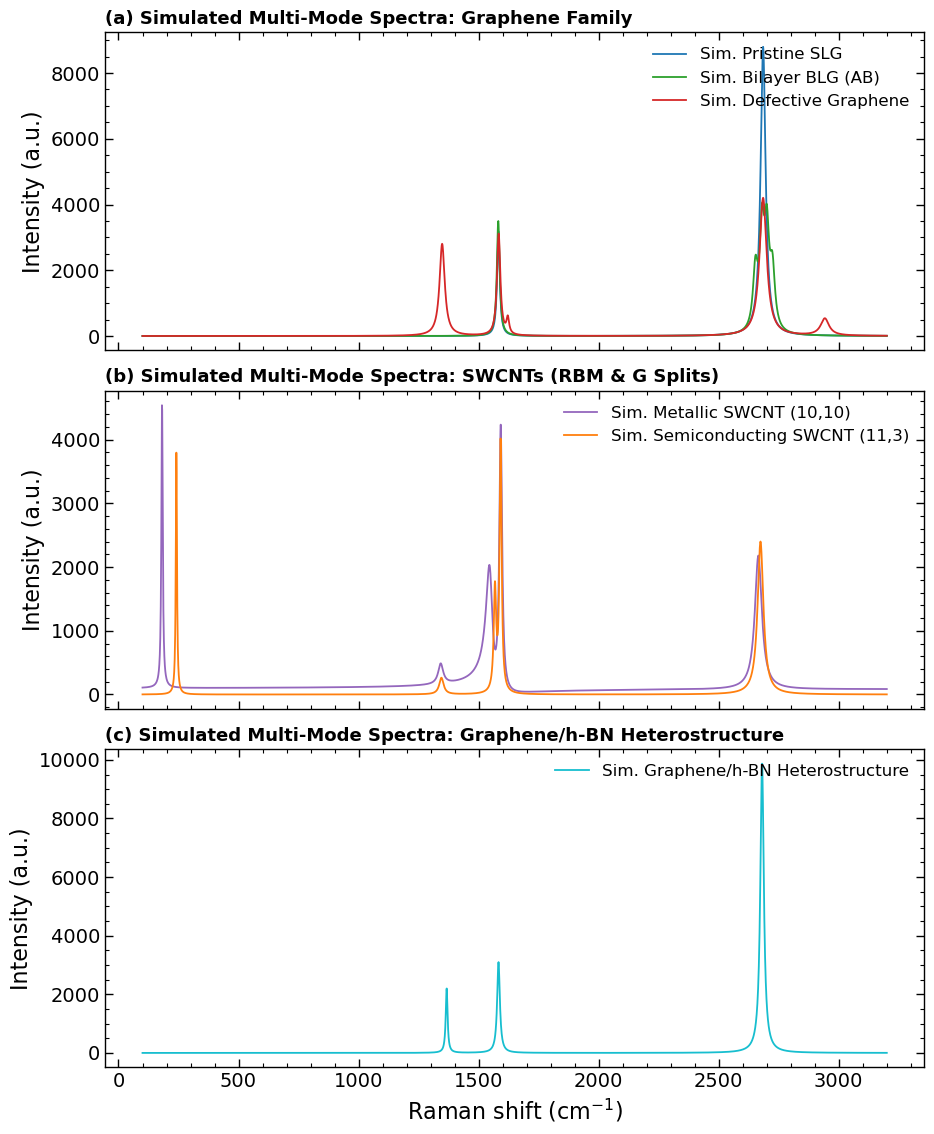

In [6]:
fig, axs = plt.subplots(3, 1, figsize=(9.5, 11.5), sharex=True)

# Graphene
ax = axs[0]
ax.plot(wn_grid, sim_outputs["graphene_pristine"]["intensity"], color=COLORS["graphene"], lw=1.3, label="Sim. Pristine SLG")
ax.plot(wn_grid, sim_outputs["graphene_bilayer"]["intensity"], color=COLORS["graphene_bilayer"], lw=1.3, label="Sim. Bilayer BLG (AB)")
ax.plot(wn_grid, sim_outputs["graphene_defective"]["intensity"], color=COLORS["graphene_defective"], lw=1.3, label="Sim. Defective Graphene")
apply_axes_style(ax, xlabel="", ylabel="Intensity (a.u.)")
ax.set_title("(a) Simulated Multi-Mode Spectra: Graphene Family", loc="left", fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="upper right")

# SWCNTs
ax = axs[1]
ax.plot(wn_grid, sim_outputs["cnt_swcnt_metallic"]["intensity"], color=COLORS["swcnt_metallic"], lw=1.3, label="Sim. Metallic SWCNT (10,10)")
ax.plot(wn_grid, sim_outputs["cnt_swcnt_semiconducting"]["intensity"], color=COLORS["swcnt_semiconducting"], lw=1.3, label="Sim. Semiconducting SWCNT (11,3)")
apply_axes_style(ax, xlabel="", ylabel="Intensity (a.u.)")
ax.set_title("(b) Simulated Multi-Mode Spectra: SWCNTs (RBM & G Splits)", loc="left", fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="upper right")

# Heterostructure
ax = axs[2]
ax.plot(wn_grid, sim_outputs["graphene_hbn"]["intensity"], color=COLORS["graphene_hbn"], lw=1.3, label="Sim. Graphene/h-BN Heterostructure")
apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (a.u.)")
ax.set_title("(c) Simulated Multi-Mode Spectra: Graphene/h-BN Heterostructure", loc="left", fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="upper right")

save_publication_figure(fig, "simulation_multimode_overview")
plt.show()

### 7. Kesimpulan Simulasi Fisika Molekular
1. Penurunan konstanta pegas ikatan $k_{C=C} \approx 885.5\text{ N/m}$ dan $k_{B-N} \approx 671.0\text{ N/m}$ merefleksikan kekuatan ikatan kovalen $sp^2$ dalam kisi heksagonal 2D.
2. Rasio anti-Stokes terhadap Stokes terbukti sangat sensitif terhadap temperatur, memvalidasi termometri fonon berbasis Raman.
3. Dispersi resonansi ganda pita 2D $\approx 100\text{ cm}^{-1}/\text{eV}$ secara akurat mereproduksi pergeseran posisi pita terhadap energi eksitasi foton.
4. Model forward berhasil membangun seluruh fitur spektral kritis: pemisahan pita $2D$ pada bilayer, kopling asimetris BWF pada nanotube logam, dan ketajaman fonon pada heterostruktur h-BN.